# Classification of Financial News by Investment Sentiment

Capstone Project

Author: Kloppertants German

Track: Classic ML

In [ ]:
# Uncomment only if packages are missing

# !pip install gradio

# Imports

In [ ]:
import pandas as pd
import numpy as np

import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.svm import LinearSVC

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# pip install xgboost
from xgboost import XGBClassifier

from sklearn.preprocessing import LabelEncoder

import gradio as gr
import joblib

In [3]:
df = pd.read_csv(
    "financial_news.csv",
    encoding="latin-1",
    header=None,
    names=["sentiment", "text"]
)

In [4]:
df.head()

,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  4846 non-null   object
 1   text       4846 non-null   object
dtypes: object(2)
memory usage: 75.8+ KB


In [6]:
df.shape

(4846, 2)

In [7]:
df.isnull().sum()

sentiment    0
text         0
dtype: int64

In [8]:
df["sentiment"].value_counts()

sentiment
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Датасет является несбалансированным, поэтому в качестве основной метрики используется F1-score вместо Accuracy.

In [9]:
df.sample(10)

,sentiment,text
1051,positive,"Last year , Lemminkainen completed the Kouvola..."
3904,neutral,The solution is demonstrated on a tablet devel...
1580,neutral,Pharmaceuticals - Netherlands This brand-new m...
1233,neutral,Goodwill and other intangible assets account f...
1462,neutral,Approval by shareholders of Cencorp in accorda...
3543,negative,Biohit said that it will reduce the number of ...
212,positive,"In December alone , the members of the Lithuan..."
3645,neutral,Inha Works has invested in its product develop...
15,positive,Consolidated net sales increased 16 % to reach...
3287,neutral,The name of the buyer was not disclosed .


# EDA

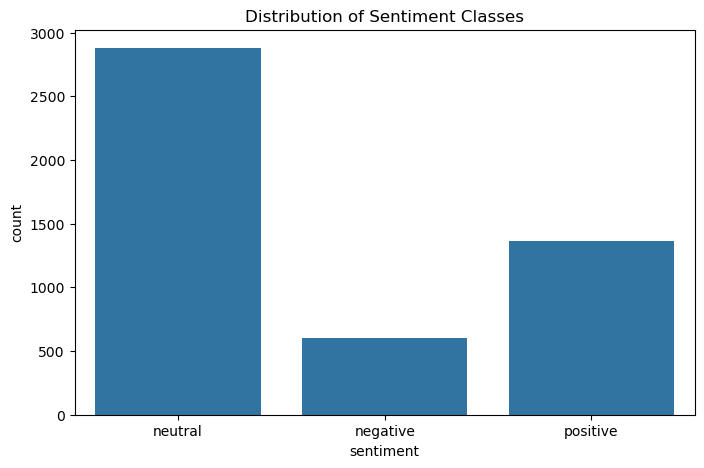

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Distribution of Sentiment Classes")
plt.show()

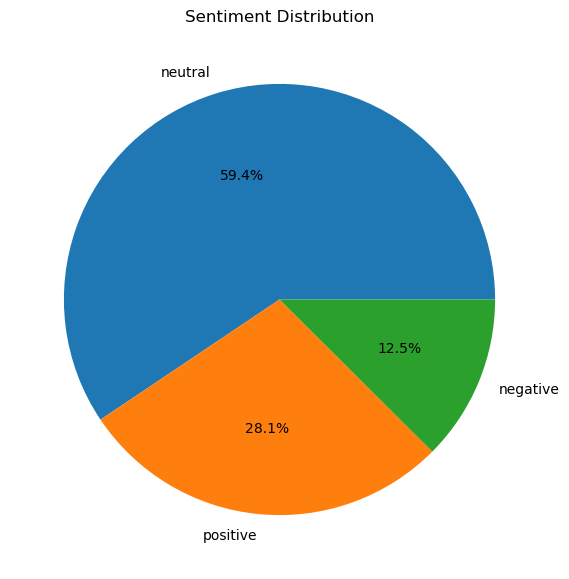

In [11]:
sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%"
)

plt.title("Sentiment Distribution")
plt.show()

In [12]:
df["text_length"] = df["text"].apply(len)
df["text_length"].describe()

count    4846.000000
mean      128.132068
std        56.526180
min         9.000000
25%        84.000000
50%       119.000000
75%       163.000000
max       315.000000
Name: text_length, dtype: float64

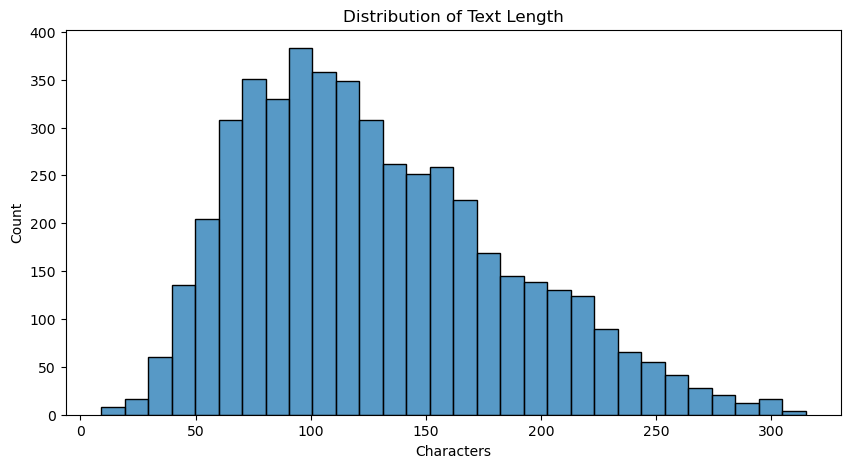

In [13]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["text_length"],
    bins=30
)

plt.title("Distribution of Text Length")
plt.xlabel("Characters")
plt.ylabel("Count")

plt.show()

Большинство новостей содержат от 50 до 150 символов, что подтверждает использование коротких заголовков в качестве входных данных.

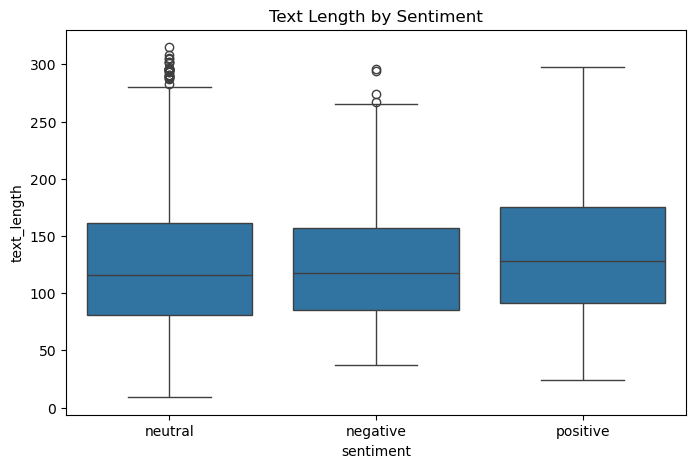

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="text_length"
)

plt.title("Text Length by Sentiment")

plt.show()

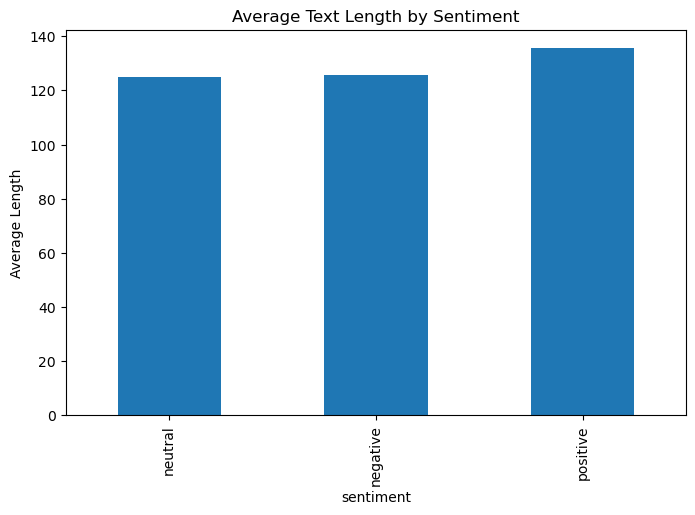

In [15]:
avg_length = (
    df.groupby("sentiment")["text_length"]
      .mean()
      .sort_values()
)

avg_length.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Average Text Length by Sentiment")
plt.ylabel("Average Length")
plt.show()

In [16]:
df.groupby("sentiment")["text_length"].mean()

sentiment
negative    125.756623
neutral     125.072247
positive    135.647836
Name: text_length, dtype: float64

Позитивные новости в среднем оказываются длиннее негативных.

In [17]:
all_text = " ".join(df["text"])

In [18]:
from collections import Counter
import re

words = re.findall(r"\b[a-zA-Z]+\b", all_text.lower())

word_freq = Counter(words)

top_words = word_freq.most_common(20)

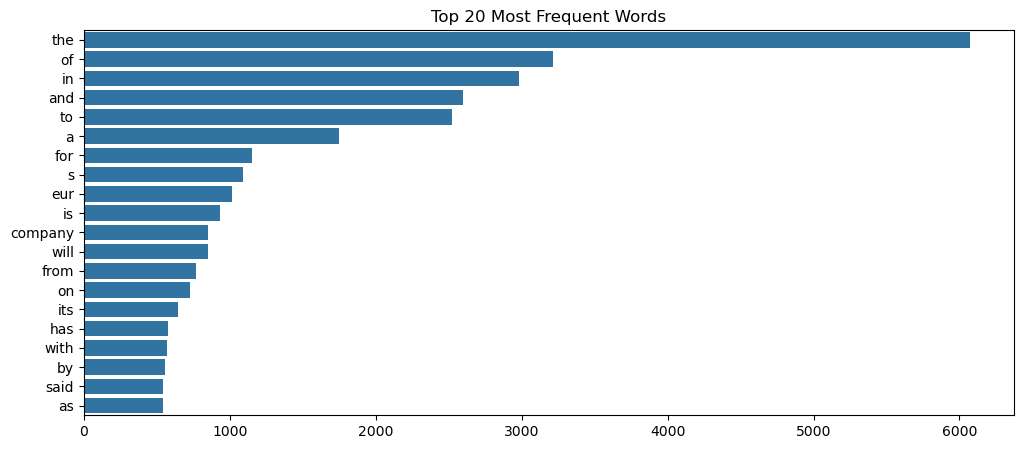

In [19]:
words = [w[0] for w in top_words]
freqs = [w[1] for w in top_words]

plt.figure(figsize=(12,5))

sns.barplot(
    x=freqs,
    y=words
)

plt.title("Top 20 Most Frequent Words")

plt.show()

In [20]:
df.groupby("sentiment")["text_length"].mean()

sentiment
negative    125.756623
neutral     125.072247
positive    135.647836
Name: text_length, dtype: float64

### Вывод
#### Датасет несбалансирован, поэтому Accuracy не является достаточной метрикой и требуется использование F1-score, Precision и Recall.


# Text Preprocessing

In [21]:
import re

def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+", "", text)

    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [22]:
df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,"According to Gran , the company has no plans t...",according to gran the company has no plans to ...
1,Technopolis plans to develop in stages an area...,technopolis plans to develop in stages an area...
2,The international electronic industry company ...,the international electronic industry company ...
3,With the new production plant the company woul...,with the new production plant the company woul...
4,According to the company 's updated strategy f...,according to the company s updated strategy fo...


In [23]:
X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Поскольку классы распределены неравномерно, использовалось стратифицированное разделение выборки для сохранения исходного распределения классов в train и test наборах.

In [24]:
X_train.shape
X_test.shape
y_train.value_counts()
y_test.value_counts()

sentiment
neutral     576
positive    273
negative    121
Name: count, dtype: int64

# TF-IDF

In [25]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

In [26]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(3876, 5000)
(970, 5000)


# baseline logistic regression

In [27]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [28]:
y_pred = baseline_model.predict(X_test_tfidf)

In [29]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        y_pred,
        average="macro"
    )
)

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred,
        average="macro"
    )
)


print(
    "Recall:",
    recall_score(
        y_test,
        y_pred,
        average="macro"
    )
)

print(
    classification_report(
        y_test,
        y_pred
    )
)

Accuracy: 0.7402061855670103
F1 Score: 0.6463711896038337
Precision: 0.7273700880338124
Recall: 0.6121660326205781
              precision    recall  f1-score   support

    negative       0.71      0.43      0.54       121
     neutral       0.75      0.93      0.83       576
    positive       0.72      0.48      0.57       273

    accuracy                           0.74       970
   macro avg       0.73      0.61      0.65       970
weighted avg       0.74      0.74      0.72       970



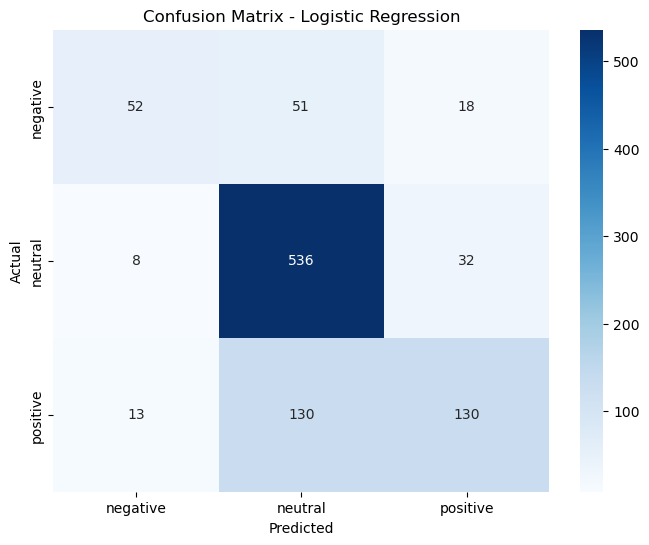

In [30]:
cm = confusion_matrix(
    y_test,
    y_pred
)
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=baseline_model.classes_,
    yticklabels=baseline_model.classes_
)

plt.title(
    "Confusion Matrix - Logistic Regression"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [90]:
baseline_results = {
    "Model":"Logistic Regression",
    "F1":0.646
}

# Improved Model #1

In [31]:
baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

baseline_model.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [32]:
y_pred = baseline_model.predict(X_test_tfidf)

In [33]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        y_pred,
        average="macro"
    )
)

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred,
        average="macro"
    )
)


print(
    "Recall:",
    recall_score(
        y_test,
        y_pred,
        average="macro"
    )
)

print(
    classification_report(
        y_test,
        y_pred
    )
)

Accuracy: 0.7164948453608248
F1 Score: 0.6722928567041336
Precision: 0.6611628359550029
Recall: 0.6881535972445064
              precision    recall  f1-score   support

    negative       0.56      0.69      0.61       121
     neutral       0.80      0.78      0.79       576
    positive       0.62      0.60      0.61       273

    accuracy                           0.72       970
   macro avg       0.66      0.69      0.67       970
weighted avg       0.72      0.72      0.72       970



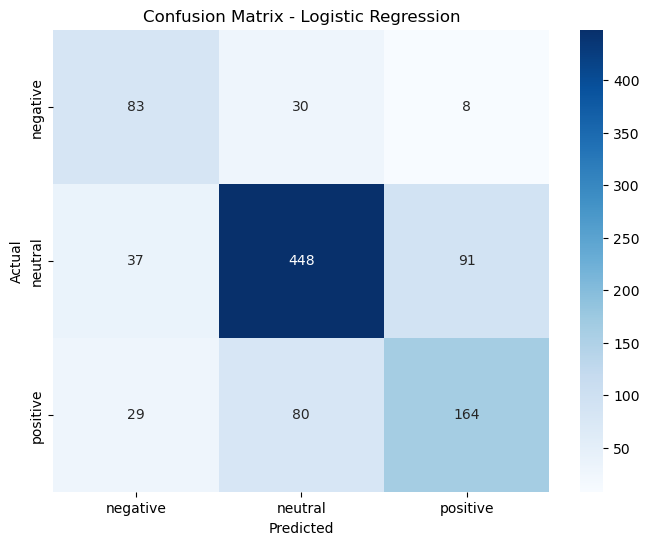

In [34]:
cm = confusion_matrix(
    y_test,
    y_pred
)
plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=baseline_model.classes_,
    yticklabels=baseline_model.classes_
)

plt.title(
    "Confusion Matrix - Logistic Regression"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Для борьбы с дисбалансом классов была протестирована Logistic Regression с параметром class_weight="balanced". Несмотря на небольшое снижение Accuracy, значение F1-score увеличилось с 0.646 до 0.672. Особенно заметное улучшение наблюдается для классов Positive и Negative, которые были представлены меньшим количеством примеров. Поэтому данная версия модели была выбрана в качестве улучшенного baseline.

### Сводная таблица результатов

| Алгоритм | Accuracy | F1-Macro |
| --- | --- | --- |
| Logistic Regression | 0.740 | 0.646 |
| Logistic Regression (balanced) | 0.716 | 0.672 |


# Improved Model #2

## XGBoost

In [35]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(
    df["sentiment"]
)

label_encoder.classes_

array(['negative', 'neutral', 'positive'], dtype=object)

In [38]:
X = df["clean_text"]
y = y_encoded

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [39]:
xgb_model = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42
)

In [41]:
xgb_model.fit(
    X_train_tfidf,
    y_train
)



XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_class=3, ...)

In [42]:
y_pred_xgb = xgb_model.predict(
    X_test_tfidf
)

In [43]:
accuracy_score(y_test, y_pred_xgb)

f1_score(
    y_test,
    y_pred_xgb,
    average="macro"
)

0.657287534905504

### Сводная таблица результатов

| Алгоритм | Accuracy | F1-Macro |
| --- | --- | --- |
| Logistic Regression | 0.74 | 0.646 |
| Logistic Regression (balanced) | 0.72 | 0.672 |
| Logistic Regression | 0.71 | 0.657 |

# Improved Model #3

# Improved Model — Balanced Logistic Regression

In [139]:
tfidf_balanced = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

balanced_model = LogisticRegression(

    class_weight="balanced",

    max_iter=2000
)

balanced_model.fit(
    X_train_tfidf,
    y_train
)



LogisticRegression(class_weight='balanced', max_iter=2000)

In [140]:
balanced_results = {

    "Model":"Balanced Logistic",

    "F1":0.672


}

# Experiment 1 — Improved TF-IDF

In [85]:
tfidf_exp = TfidfVectorizer(

    max_features=10000,

    stop_words="english",

    ngram_range=(1,2),

    min_df=2,

    max_df=0.95,

    sublinear_tf=True
)

X_train_exp = tfidf_exp.fit_transform(
    X_train
)

X_test_exp = tfidf_exp.transform(
    X_test
)

In [86]:
exp_model = LogisticRegression(

    max_iter=2000,

    class_weight="balanced",

    C=2
)

exp_model.fit(
    X_train_exp,
    y_train
)

LogisticRegression(C=2, class_weight='balanced', max_iter=2000)

In [87]:
pred_exp = exp_model.predict(
    X_test_exp
)

exp_f1 = f1_score(
    y_test,
    pred_exp,
    average="macro"
)

print(exp_f1)

0.6856195773669808


In [88]:
experiment_1 = {
    "Model":"TF-IDF Tuned",
    "F1":exp_f1
}

# Experiment 2 — Hyperparameter Tuning

In [106]:
params = {

    "C": [
        0.1,
        0.5,
        1,
        2,
        5,
        10
    ],

    "class_weight": [
        None,
        "balanced"
    ],

    "solver": [
        "lbfgs"
    ]

}

In [109]:
grid = GridSearchCV(

    LogisticRegression(
        max_iter=3000
    ),

    param_grid=params,

    cv=5,

    scoring="f1_macro",

    n_jobs=-1,

    verbose=1
)

In [110]:
grid.fit(
    X_train_exp,
    y_train
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5, estimator=LogisticRegression(max_iter=3000), n_jobs=-1,
             param_grid={'C': [0.1, 0.5, 1, 2, 5, 10],
                         'class_weight': [None, 'balanced'],
                         'solver': ['lbfgs']},
             scoring='f1_macro', verbose=1)

In [111]:
print("Best params:")

print(
    grid.best_params_
)

print()

print(
    "CV score:",
    grid.best_score_
)

Best params:
{'C': 5, 'class_weight': 'balanced', 'solver': 'lbfgs'}

CV score: 0.6911199627184575


In [112]:
best_lr = grid.best_estimator_

In [113]:
pred = best_lr.predict(
    X_test_exp
)

f1_lr = f1_score(
    y_test,
    pred,
    average="macro"
)

print(
    "F1:",
    f1_lr
)

F1: 0.6947374247883585


# Final Model 

In [116]:
svm = LinearSVC(

    C=1,

    class_weight="balanced",

    max_iter=10000
)

In [117]:
svm.fit(
    X_train_exp,
    y_train
)

LinearSVC(C=1, class_weight='balanced', max_iter=10000)

In [118]:
pred = svm.predict(
    X_test_exp
)

f1_svm = f1_score(
    y_test,
    pred,
    average="macro"
)

print(
    "LinearSVC F1:",
    f1_svm
)

LinearSVC F1: 0.7015457599578919


In [141]:
final_model = svm

final_vectorizer = tfidf_exp

print(
    "Final model selected:",
    type(final_model).__name__
)

Final model selected: LinearSVC


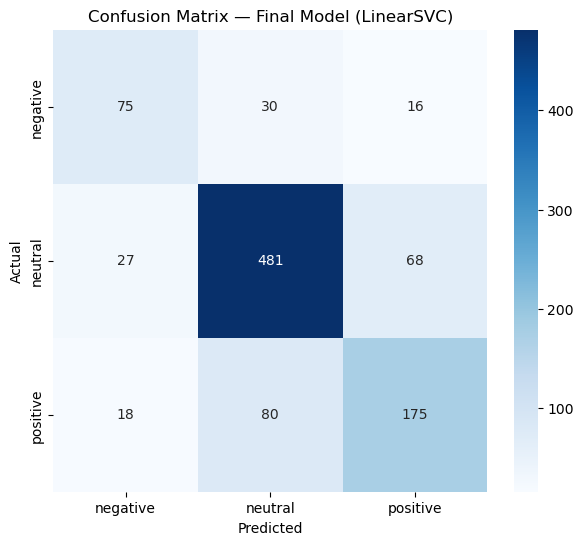

In [162]:
# Confusion Matrix — Final Model

X_test_clean = X_test.apply(
    clean_text
)

X_test_vector = final_vectorizer.transform(
    X_test_clean
)

pred = final_model.predict(
    X_test_vector
)

cm = confusion_matrix(
    y_test,
    pred
)

labels = label_encoder.inverse_transform(
    sorted(
        np.unique(y_test)
    )
)

plt.figure(
    figsize=(7,6)
)

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=labels,

    yticklabels=labels

)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "Confusion Matrix — Final Model (LinearSVC)"
)

plt.show()

# Model Comparison

In [119]:
results = pd.DataFrame({

"Model":[

"Baseline LR",

"Balanced LR",

"XGBoost",

"Tuned TF-IDF",

"GridSearch LR",

"LinearSVC"

],

"F1":[

0.646,

0.672,

0.657,

0.686,

f1_lr,

f1_svm

]

})

results

,Model,F1
0,Baseline LR,0.646000
1,Balanced LR,0.672000
2,XGBoost,0.657000
3,Tuned TF-IDF,0.686000
4,GridSearch LR,0.694737
5,LinearSVC,0.701546


<Axes: xlabel='Model', ylabel='F1'>

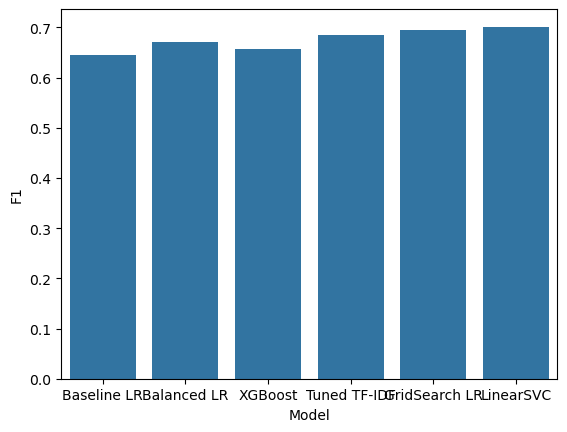

In [120]:
sns.barplot(
    data=results,
    x="Model",
    y="F1"
)

# Error Analysis

In [143]:
X_test_clean = X_test.apply(
    clean_text
)

X_test_vector = final_vectorizer.transform(
    X_test_clean
)

predictions = final_model.predict(
    X_test_vector
)

errors = pd.DataFrame({

    "news": X_test.values,

    "actual": y_test,

    "predicted": predictions

})

In [144]:
errors["actual"] = label_encoder.inverse_transform(
    errors["actual"]
)

errors["predicted"] = label_encoder.inverse_transform(
    errors["predicted"]
)

In [145]:
errors = errors[
    errors["actual"] != errors["predicted"]
]

errors.shape

(239, 3)

In [146]:
errors.head(10)

,news,actual,predicted
15,for nordea moving into the new headquarters si...,positive,neutral
36,after non recurring items of eur mn profit amo...,neutral,negative
38,the company expects its net sales in the first...,positive,negative
40,more staff has been recruited in japan to furt...,positive,negative
41,combining this deep domain expertise with our ...,positive,neutral
44,the company is also featured in the ethibel pi...,positive,neutral
45,paper maker stora enso oyj said friday it has ...,positive,neutral
49,the newly created position has been establishe...,positive,neutral
50,apartments of yit home may be purchased in reg...,neutral,positive
52,due to rapid expansion the market share of tal...,positive,negative


In [147]:
for i, row in errors.head(10).iterrows():

    print("="*100)

    print("\nNEWS:\n")

    print(row["news"])

    print("\nREAL:")

    print(row["actual"])

    print("\nPREDICTED:")

    print(row["predicted"])

    print()


NEWS:

for nordea moving into the new headquarters signifies the beginning of a new era

REAL:
positive

PREDICTED:
neutral


NEWS:

after non recurring items of eur mn profit amounted to eur mn

REAL:
neutral

PREDICTED:
negative


NEWS:

the company expects its net sales in the first half of to reach the previous year s level

REAL:
positive

PREDICTED:
negative


NEWS:

more staff has been recruited in japan to further complement its network of close to service locations in more than countries worldwide

REAL:
positive

PREDICTED:
negative


NEWS:

combining this deep domain expertise with our application service management asm and outsourcing service offerings has now proved to be a winning combination

REAL:
positive

PREDICTED:
neutral


NEWS:

the company is also featured in the ethibel pioneer investment register and included in innovest s global list of the world s most sustainable corporations

REAL:
positive

PREDICTED:
neutral


NEWS:

paper maker stora enso oyj said frida

In [148]:
errors.groupby(
    ["actual","predicted"]
).size().sort_values(
    ascending=False
)

actual    predicted
positive  neutral      80
neutral   positive     68
negative  neutral      30
neutral   negative     27
positive  negative     18
negative  positive     16
dtype: int64

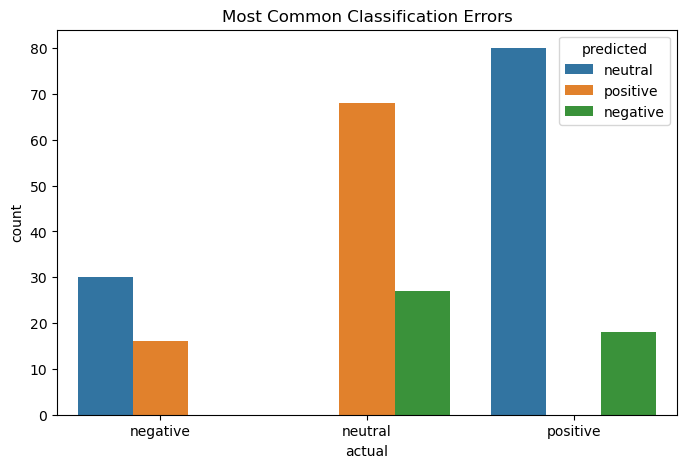

In [149]:
mistakes = (
    errors
    .groupby(
        ["actual","predicted"]
    )
    .size()
    .reset_index(
        name="count"
    )
)

plt.figure(
    figsize=(8,5)
)

sns.barplot(
    data=mistakes,
    x="actual",
    y="count",
    hue="predicted"
)

plt.title(
    "Most Common Classification Errors"
)

plt.show()

Анализ ошибок показал, что модель чаще всего ошибается между классами Neutral и Positive. Наиболее распространёнными ошибками стали случаи классификации нейтральных новостей как позитивных (91 случай) и позитивных как нейтральных (80 случаев).

Это объясняется тем, что финансовые новости часто содержат нейтральные формулировки, включающие слова, ассоциируемые с положительной динамикой («growth», «increase», «gain»), что приводит к смещению предсказаний.

Ошибки между Positive и Negative встречались значительно реже, что указывает на способность модели различать явно позитивные и негативные финансовые события.

Таким образом, основной сложностью задачи является разграничение слабовыраженной позитивной тональности и нейтральных сообщений.


# Prediction System

In [163]:
def predict_news(news):

    cleaned = clean_text(news)

    vector = final_vectorizer.transform(
        [cleaned]
    )

    pred = final_model.predict(
        vector
    )[0]

    scores = final_model.decision_function(
        vector
    )[0]

    confidence = (
        np.max(scores)
        -
        np.min(scores)
    )

    confidence = (
        confidence
        /
        (
            confidence
            +
            1
        )
    )

    sentiment = label_encoder.inverse_transform(
        [pred]
    )[0]

    return sentiment, confidence

In [165]:
def show_prediction(news):

    sentiment, confidence = predict_news(
        news
    )

    emoji = {

        "positive":"📈",

        "negative":"📉",

        "neutral":"➖"

    }

    print(
        "\nFinancial News:\n"
    )

    print(
        news
    )

    print(
        "\nPrediction:\n"
    )

    print(

        emoji[sentiment],

        sentiment.upper()

    )

    print(
        f"\nConfidence: {confidence:.1%}"
    )

### Вводим заголовок новости которая нас интересует. ( Только на Английском языке)

In [166]:
show_prediction(
    "Tesla reports record quarterly earnings"
)


Financial News:

Tesla reports record quarterly earnings

Prediction:

📈 POSITIVE

Confidence: 68.2%


In [167]:
examples = [

"Tesla reports record quarterly earnings",

"Company cuts future revenue forecast",

"New production facility opens",

"Stock falls after disappointing results",

"Firm maintains previous expectations"

]

In [168]:
for news in examples:

    show_prediction(news)

    print()

    print("-"*40)


Financial News:

Tesla reports record quarterly earnings

Prediction:

📈 POSITIVE

Confidence: 68.2%

----------------------------------------

Financial News:

Company cuts future revenue forecast

Prediction:

📉 NEGATIVE

Confidence: 41.3%

----------------------------------------

Financial News:

New production facility opens

Prediction:

➖ NEUTRAL

Confidence: 49.3%

----------------------------------------

Financial News:

Stock falls after disappointing results

Prediction:

➖ NEUTRAL

Confidence: 45.6%

----------------------------------------

Financial News:

Firm maintains previous expectations

Prediction:

➖ NEUTRAL

Confidence: 62.6%

----------------------------------------


### Ошибка 

Новость - Stock falls after disappointing results

Ожидаем - Negative . Модель определила как - Neutral

Модель склонна предсказывать класс Neutral из-за дисбаланса данных и недостаточного количества выраженных негативных примеров.

# Demo Interface (Gradio)

In [169]:
def predict_interface(news):

    sentiment, confidence = predict_news(
        news
    )

    return (

        f"Prediction: "

        f"{sentiment.upper()}\n\n"

        f"Confidence: "

        f"{confidence:.1%}"

    )

In [170]:
demo = gr.Interface(

    fn=predict_interface,

    inputs=gr.Textbox(
        lines=3,
        label="Financial News Headline"
    ),

    outputs=gr.Textbox(
        label="Prediction"
    ),

    title="Financial News Sentiment Classifier",

    description=(
        "Enter an English financial news headline "
        "to classify investment sentiment."
    )

)

In [171]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


c:\Users\grk28\anaconda3\Lib\site-packages\gradio\routes.py:1379: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


# Save Model

In [158]:
#pip install joblib
import joblib

joblib.dump(
    final_model,
    "financial_sentiment_model.pkl"
)

joblib.dump(
    final_vectorizer,

    "tfidf_vectorizer.pkl"
)

joblib.dump(
    label_encoder,
    "label_encoder.pkl"
)



['label_encoder.pkl']

In [159]:
os.listdir()

['.gradio',
 'financial_news.csv',
 'financial_news_sentiment_project.ipynb',
 'financial_sentiment_model.pkl',
 'label_encoder.pkl',
 'tfidf_vectorizer.pkl']

# Load Saved Model

In [160]:
loaded_model = joblib.load(
    "financial_sentiment_model.pkl"
)

loaded_tfidf = joblib.load(
    "tfidf_vectorizer.pkl"
)

loaded_encoder = joblib.load(
    "label_encoder.pkl"
)

In [161]:
text = "Tesla reports record quarterly earnings"

vector = loaded_tfidf.transform(
    [clean_text(text)]
)

pred = loaded_model.predict(
    vector
)[0]

loaded_encoder.inverse_transform(
    [pred]
)

array(['positive'], dtype=object)